# Study 2: selective JEV routing against a verified human reference

**Executed development-and-protocol package. Fresh Study 2 outcomes are not
available in the delivered snapshot. No cached result is presented as fresh
validation.** The owner has authorized up to **10,000 additional live JEV
attempts**. A separate resumable collection command uses that authorization once
the scientific, data, access and authentication prerequisites are available;
routine notebook reruns remain offline.

The intended question is whether selective JEV assistance reduces false-positive
post flags per 1,000 compared with tuned XGBoost while estimating sensitivity
against a verified, construct-compatible human reference. A nonsignificant
sensitivity difference is not evidence of preservation. A negative or
inconclusive result would be reported without changing the operating point.

Primary source supplied by the owner:
<https://ieeexplore.ieee.org/document/9591887>. Primary-source access, annotation
unit and exact linkage to the repository's Kaggle release remain unresolved.
The distinction between expert-rated posts, author-level labels and supplied
binary text labels determines what the study can claim.

In [1]:
%matplotlib inline
from pathlib import Path
import json,sys,re,subprocess
import unittest.mock as mock
import pandas as pd
import numpy as np
from IPython.display import display,Markdown,Image
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'jev_research').is_dir())
sys.path.insert(0,str(ROOT))
from jev_research.study2 import run_offline,STUDY,ATTEMPT_CEILING
from jev_research.study2_outputs import replay_fresh_if_complete,write_report,make_figures
from jev_research.budgeted_experiments import digest,file_digest,save_json
from jev_research.study2_collection import ledger_status
RANDOM_SEED=42
RUN_LIVE_COLLECTION_FROM_NOTEBOOK=False
assert RUN_LIVE_COLLECTION_FROM_NOTEBOOK is False
guard=mock.patch('requests.sessions.Session.request',side_effect=RuntimeError('Offline notebook: HTTP disabled'))
guard.start()
private=ROOT/'artifacts'/STUDY;private.mkdir(parents=True,exist_ok=True)
protected=[ROOT/'assets/notebooks'/name for name in ['jev_probability_hybrid_5000.ipynb','jev_probability_hybrid_budgeted_experiments.ipynb']]
for name in ['jev_probability_hybrid','jev_probability_hybrid_budgeted_experiments']:
    protected.extend(p for p in (ROOT/'research/results'/name).rglob('*') if p.is_file())
before={str(p.relative_to(ROOT)):file_digest(p) for p in protected}
study=run_offline(ROOT)
results=study['results']
status=replay_fresh_if_complete(ROOT)
reviewer=write_report(study,status)
figures=make_figures(study)
display(pd.Series(status,name='Actual Study 2 execution status'))
print('Already authorized ceiling:',ATTEMPT_CEILING)
print('No collection function is invoked by this notebook.')

actual_new_attempts                                                                  0
successes                                                                            0
failed                                                                               0
pending_uncertain                                                                    0
unused_allowance                                                                 10000
ledger_exists                                                                    False
study_id                                       jev_selective_routing_study2_validation
analysis_status                                                          NOT COLLECTED
fresh_effect                                                                      None
sensitivity_preservation             not adjudicated; no fresh reference data or ju...
selective_beats_equal_cost_random                                        not estimable
Name: Actual Study 2 execution status, dtyp

Already authorized ceiling: 10000
No collection function is invoked by this notebook.


## 1. What exactly do the human labels measure?

The paper must be the primary evidence for its annotation claims. The available
repository identifies a CSV release and binary mapping, but does not document
specialist qualifications, rating context, item-level coverage, agreement or a
paper-to-record join. The owner did not know where a mapping was stored or
whether raters saw posts or authors with multiple posts. That reply is recorded
as missing provenance, not as evidence that specialists were absent.

In this environment, the IEEE document, Kaggle documentation and Crossref
metadata requests returned proxy CONNECT 403 errors. No paper title, DOI,
collection period, license, rater count or agreement value is inferred from a
document number. No copy of the paper, supplement, CSV or mapping was found in
the available project files. Matched and unmatched record counts are **not
estimable**, which is different from establishing zero matches.

Suicide-related discussion, self-reported ideation, expressed intent,
expert-assessed risk and an observed future outcome are different constructs.
If a paper labels an author after reading several posts, inheriting that label
for every post does not establish an expert assessment of each isolated text.
The model currently receives a single original text; the rater's context is
unknown. No future suicide outcome, intervention benefit or diagnosis is
measured by the supplied binary exports.

Here "post" is an operational shorthand for one exported text record in the
intended review task. Its equivalence to a single original source post is not
verified. This shorthand does not convert an author/collection rating into an
expert annotation of an individual post.

In [2]:
display(study['tables']['provenance'])
access=json.loads((results/'access_and_mapping_audit.json').read_text())
display(pd.DataFrame(access['source_access']))
print('Owner mapping response:',access['mapping_owner_reply'])
print('Credential binding at inspection:',access['runtime_bindings']['METIS_API_KEY'])
print('Saved environment requirements are a draft; they did not apply runtime networking or supply a key.')

,provenance_item,finding,evidence_and_limit
0,Citation / DOI,https://ieeexplore.ieee.org/document/9591887,"IEEE article title, authors and DOI not retrie..."
1,Release,Kaggle nikhileswarkomati/suicide-watch version 14,Repository README and saved dataset fingerprin...
2,Dataset checksum,1ec16b065a2fae36488de16e8abfc326586a576a25901e...,Saved provenance only; original CSV absent
3,Language / platform / period,Not independently verified from primary source,Pipeline assumes English; no source collection...
4,Sampling / access / license,Not verified,Kaggle/IEEE access blocked; do not infer a lic...
5,Annotation unit / rater context,Unknown: posts versus authors or post collecti...,Owner does not know the mapping or rating unit
6,Construct / operational definition,Supplied binary suicide/non-suicide labels only,"Expert risk, expressed intent, ideation and fu..."
7,Qualifications / raters per item,Not reported in available project artifacts,Primary paper unread; absence from exports doe...
8,Instructions / adjudication / agreement,Not ascertainable,No primary annotation protocol or supplementar...
9,Coverage of specialist labels,Unverified,"Cannot establish entire release, a subset or a..."


,url,result,retrieved
0,https://ieeexplore.ieee.org/document/9591887,proxy_CONNECT_403,False
1,https://www.kaggle.com/datasets/nikhileswarkom...,proxy_CONNECT_403,False
2,https://api.crossref.org/works?query=9591887&r...,proxy_CONNECT_403,False


Owner mapping response: Owner does not know where a record mapping is held or whether specialists labeled posts or authors.
Credential binding at inspection: unset
Saved environment requirements are a draft; they did not apply runtime networking or supply a key.


## 2. Reproduce Study 1 and use it only for development

The two executed notebooks and their underlying policy, parser and routing code
were inspected. The current replay recomputes the historical hash split of
2,000 development and 3,000 evaluation records and chooses cutoffs on the former
only, matching the original exploratory comparison. All four original failed
requests remain XGB@0.50 fallbacks. These are historical checks, not a new study.

For Study 2 planning all 5,000 inspected probability-selected records can now be
used as development. Earlier error-only selections remain separate because
known errors determined their sampling. The old raw-text/cleaned-text checks
cannot be rerun without private source tables. Source inspection shows English
preprocessing, train-only learned Word2Vec features/XGBoost, global raw conflict
filtering before stratification, and cleaned duplicate removal with training
priority. Author/time separation is not established by those checks.

In [3]:
historical=study['tables']['historical_reference_checks']
display(historical[['evidence','policy','development_target_recall','threshold','n','recall','precision','fn','fp','prospective_requests']])
display(historical.loc[historical.policy.eq('JEV replacement'),
    ['development_target_recall','delta_recall','delta_recall_ci_low','delta_recall_ci_high',
     'delta_precision','delta_precision_ci_low','delta_precision_ci_high']])
print('All figures above are recomputed from saved per-example records, not hard-coded predictions.')

,evidence,policy,development_target_recall,threshold,n,recall,precision,fn,fp,prospective_requests
0,"Study 1 reused exploratory 3,000 text records;...",XGBoost,0.90,0.342598,3000,0.887995,0.586912,181,1010,0
1,"Study 1 reused exploratory 3,000 text records;...",JEV replacement,0.90,0.080000,3000,0.887995,0.777778,181,410,3000
2,"Study 1 reused exploratory 3,000 text records;...",XGBoost,0.95,0.293316,3000,0.954208,0.563803,74,1193,0
3,"Study 1 reused exploratory 3,000 text records;...",JEV replacement,0.95,0.030000,3000,0.960396,0.712908,64,625,3000


,development_target_recall,delta_recall,delta_recall_ci_low,delta_recall_ci_high,delta_precision,delta_precision_ci_low,delta_precision_ci_high
1,0.90,0.000000,-0.020484,0.020837,0.190866,0.173847,0.208034
3,0.95,0.006188,-0.007985,0.019351,0.149105,0.135779,0.162399


All figures above are recomputed from saved per-example records, not hard-coded predictions.


## 3. Audit repeated JEV observations before buying repeats

Join the two old exports by exact text SHA-256 and compare binary decisions at
the candidate low cutoffs and at 0.50. A numerical score discrepancy need not
change a decision. Report the 21-text denominator, both directions of switching
and Wilson intervals rather than treating 11 changed scores as 11 clinical
decision changes. This overlap is an error-enriched, nonrepresentative subset;
its interval is descriptive and cannot establish population-wide stability.

The mutable `jev-latest` alias has no recorded immutable backend revision. The
exports alone cannot distinguish stochastic inference from backend changes.
Zero changed decisions in a small selected repeat set also cannot prove
deterministic behavior. No new paid repeat observations are planned initially.

In [4]:
display(study['tables']['historical_repeat_audit'])
print('New paid repeats collected: 0. Existing repeat evidence is used first.')

,threshold,repeated_text_n,different_score_n,different_binary_decision_n,different_binary_decision_rate,wilson95_low,wilson95_high,probability_run_positive_n,error_run_positive_n,probability_positive_error_negative_n,probability_negative_error_positive_n,scope
0,0.03,21,11,1,0.047619,0.008456,0.226694,16,17,0,1,"21 repeated, error-enriched texts; descriptive..."
1,0.08,21,11,0,0.000000,0.000000,0.154639,13,13,0,0,"21 repeated, error-enriched texts; descriptive..."
2,0.50,21,11,0,0.000000,0.000000,0.154639,9,9,0,0,"21 repeated, error-enriched texts; descriptive..."


New paid repeats collected: 0. Existing repeat evidence is used first.


## 4. Dated internal design and one primary comparison

The saved JSON is a **dated internal design draft**, not a public preregistration
and not a collection-frozen protocol. The actual source construct, reference
mapping, sampling frame and inclusion probabilities must be verified before
that freeze. A cryptographic digest identifies the draft that exists; a digest
does not by itself make a scientifically unresolved protocol ready to collect.

The conditional primary candidate is selective replacement in [0.25,0.80) versus
threshold-tuned XGBoost. The cache supplies a 0.95 development-recall operating
point for the difficult score range, not a promised global 95% recall. Study 2
fallback retains the **tuned comparator decision**, deliberately different from
the old XGB@0.50 fallback. Prompt, rating parser, model alias and cutoffs are
recorded. Sigmoid calibration and logistic fusion remain secondary; the previous
small uncertain incremental fusion gain does not justify centering complexity.

The hypothetical task is referring flagged posts for contextual assessment by
qualified human reviewers. No deployed workflow is asserted. A flag is not a
diagnosis, proof of current intent or a prediction of a future death.

Define $\Delta_{FA}=FA_{XGB}/N\cdot1000-FA_{selective}/N\cdot1000$; positive values
favor assistance. Define $\Delta_{Se}=Se_{selective}-Se_{XGB}$. A preservation
claim would require a defensible absolute margin $\delta$ and the appropriate
paired lower confidence bound strictly above $-\delta$. No justified clinical
margin is available. Therefore preservation is **not adjudicated**; 1/2/5-point
scenarios are illustrative only. Nonsignificance is not a substitute.

In [5]:
display(pd.Series(study['candidate'],name='Conditional operating point'))
protocol=study['protocol']
display(pd.Series({k:protocol[k] for k in ['status','created_at_utc','created_at_tehran',
    'registration','annotation_unit','positive_construct','primary_effect','noninferiority_margin',
    'owner_live_authorization','evaluation_manifest_sha256']}))
print('Protocol digest:',digest(protocol))
display(pd.Series(protocol['gates'],name='Unresolved prerequisites'))

status                         conditional_candidate_not_a_frozen_evaluation_...
comparator                                               threshold-tuned XGBoost
primary_assisted                                           selective replacement
xgb_threshold                                                           0.295508
jev_threshold                                                               0.03
routing_interval                                                     [0.25, 0.8]
calibration                    none in primary policy; sigmoid/fusion are sec...
fallback                       retain comparator decision at frozen XGBoost t...
development                    all 5,000 historical cache rows; supplied labe...
development_target_recall                                                   0.95
target_scope                   historical routed score-range only; not a guar...
model                                                                 jev-latest
immutable_provider_revision 

status                        DATED_INTERNAL_DESIGN_DRAFT_NOT_FROZEN_FOR_COL...
created_at_utc                                 2026-11-16T10:29:14.260249+00:00
created_at_tehran                              2026-11-16T13:59:14.260249+03:30
registration                                  No public preregistration claimed
annotation_unit               pending primary-source verification; intended ...
positive_construct            pending source definition and paper-to-release...
primary_effect                comparator false alarms per 1000 minus selecti...
noninferiority_margin                                                      None
owner_live_authorization      Already granted up to 10000 additional attempt...
evaluation_manifest_sha256                                                 None
dtype: object

Protocol digest: 49e56e309e4e12fd41ea0b74220c2e9dc30babfef9a7192f5a02b38771c981ee


complete_sampling_frame_verified         False
expert_record_mapping_verified           False
external_transfer_terms_permit           False
frozen_manifest_and_protocol             False
live_credential_available                False
primary_source_and_construct_verified    False
Name: Unresolved prerequisites, dtype: bool

## 5. Fresh population, exclusions and precision planning

Prefer unused authors from a later period or a separate construct-compatible
expert-labeled population. With the current sources unavailable, the implemented
fallback targets genuinely unqueried old-test posts and discloses that their
labels previously contributed to aggregate baseline reports. It excludes
training/development, all earlier JEV/error-study selections and failed requests;
exact/cleaned duplicates and known prior authors are excluded where fields exist.
Near-duplicate and temporal checks remain pending actual source records.

Excluding old queried posts changes the target frame: from the published counts,
the candidate residual has 41,323 posts and 1,062 inside the old route before
further exclusions. Neither a row-level frame nor individual labels is fabricated
from this arithmetic. A four-stratum common sample includes both exterior
regions and both sides of the comparator cutoff with known inclusion
probabilities. Census the residual route where feasible and probability-sample
the exterior strata to estimate the population/random comparator.

The ceiling of 10,000 is not a quota. The following planning grid uses historical
positive prevalence and paired disagreement within the routed population, with
design-effect scenarios 1/1.5/2/4. It illustrates conditional precision; it cannot
identify outside-range disagreements or deliver a full-population power
calculation. Final quotas need the full frame and explicit precision assumptions.
No main evaluation budget is spent on an unresolved or incompatible target.

In [6]:
display(pd.Series(study['planning'],name='Planning evidence and limitations'))
display(study['tables']['illustrative_precision_planning'])
manifest_status={'version':1,'status':'pending complete frame and source verification',
    'records':None,'manifest_sha256':None,'new_evaluation_outcomes_opened':False,
    'selection_fields':['stable IDs','baseline scores','permitted metadata'],
    'forbidden_selection_fields':['evaluation labels','observed correctness','evaluation JEV scores']}
save_json(results/'sampling_manifest_status.json',manifest_status)
display(pd.Series(manifest_status))

known_original_test_n                                                                                         46342
known_original_eligible_n                                                                                      6067
previous_probability_cohort_n                                                                                  5000
additional_previous_error_test_n                                                                                 19
additional_previous_error_test_inside_interval_n                                                                  5
inferred_remaining_test_n_before_other_independence_exclusions                                                41323
inferred_remaining_eligible_n_before_other_exclusions                                                          1062
inferred_remaining_routing_fraction                                                                          0.0257
warning                                                           Exclud

,planned_common_sample_n,assumed_design_effect,assumed_positive_fraction,assumed_positive_disagreement,approx_sensitivity_halfwidth_95_pp,approx_specificity_halfwidth_95_pp,scope
0,2000,1.0,0.5446,0.083364,1.713814,3.801356,illustrative routed-population iid approximati...
1,2000,1.5,0.5446,0.083364,2.098985,4.655691,illustrative routed-population iid approximati...
2,2000,2.0,0.5446,0.083364,2.423699,5.375929,illustrative routed-population iid approximati...
3,2000,4.0,0.5446,0.083364,3.427628,7.602712,illustrative routed-population iid approximati...
4,5000,1.0,0.5446,0.083364,1.083911,2.404189,illustrative routed-population iid approximati...
5,5000,1.5,0.5446,0.083364,1.327515,2.944518,illustrative routed-population iid approximati...
6,5000,2.0,0.5446,0.083364,1.532882,3.400036,illustrative routed-population iid approximati...
7,5000,4.0,0.5446,0.083364,2.167822,4.808377,illustrative routed-population iid approximati...
8,8000,1.0,0.5446,0.083364,0.856907,1.900678,illustrative routed-population iid approximati...
9,8000,1.5,0.5446,0.083364,1.049493,2.327846,illustrative routed-population iid approximati...


version                                                                           1
status                               pending complete frame and source verification
records                                                                        None
manifest_sha256                                                                None
new_evaluation_outcomes_opened                                                False
selection_fields                  [stable IDs, baseline scores, permitted metadata]
forbidden_selection_fields        [evaluation labels, observed correctness, eval...
dtype: object

## 6. Equal-cost random referral and design-appropriate paired inference

Use a single JEV output per sampled fresh post to replay all compatible policies.
Selective and random referral share the same JEV decision threshold and fallback.
Only the referred posts differ. If the full remaining frame has $M$ routed posts
among $N$, random referral uses marginal probability $r=M/N$ under a uniform
fixed-size referral set. A raw 20% referral fraction in an oversampled difficult
subset must not be substituted for a 2.57% population budget.

For comparator decision $b_i$, successful JEV decision $g_i$ and availability
$u_i$, expected random-policy positivity is
$b_i+r\,u_i(g_i-b_i)$. Expected confusion totals identify the expected policy
counts. Precision is the ratio of expected totals, not the expectation of a
randomized precision ratio. OR queries only eligible comparator-negative posts
and cannot override comparator positives to negative. A local word/character
TF-IDF logistic baseline is implemented with training-only features and
upstream development selection, but has no real-data fit in this snapshot.

Weights are $1/\pi_i=N_h/n_h$. Report paired population estimates, difficult
stratum results, transitions, flags/errors/requests per 1,000, and false alarms
avoided plus positive detections gained/lost per 100 requests. Weighted paired
bootstrap perturbations retain strata/weights with finite-frame correction
$\sqrt{1-n_h/N_h}$. A census has zero *finite-frame sampling* variance, which
does not remove provider variability, annotation uncertainty or future-population
uncertainty. Known repeated authors require a cluster design; an unsupported
ordinary row bootstrap is refused. Ordinary exact McNemar is not used for
weighted or expected-random counts.

In [7]:
display(pd.read_json(results/'study2_main_population_results.json',precise_float=True))
display(pd.read_json(results/'study2_routing_stratum_results.json',precise_float=True))
if status['analysis_status']!='COLLECTED AND REPLAYED':
    print('The two primary Study 2 tables contain explicit NOT COLLECTED entries, not zero-effect estimates.')
    print('Main reference criterion: not adjudicated. Selective versus equal-cost random: not estimable.')

,policy,Study 2 population estimates,fresh_sample_n,false_alarms_per_1000,sensitivity,actual_new_attempts,reason
0,XGBoost tuned,NOT COLLECTED,NaN,NaN,NaN,0,"source/reference mapping, transfer terms, raw ..."
1,Selective JEV,NOT COLLECTED,NaN,NaN,NaN,0,"source/reference mapping, transfer terms, raw ..."
2,Budget-matched random,NOT COLLECTED,NaN,NaN,NaN,0,"source/reference mapping, transfer terms, raw ..."
3,One-sided OR,NOT COLLECTED,NaN,NaN,NaN,0,"source/reference mapping, transfer terms, raw ..."
4,Strong local text baseline,NOT COLLECTED,NaN,NaN,NaN,0,"source/reference mapping, transfer terms, raw ..."


,stratum,Study 2 result,observed_count
0,outside_low,NOT COLLECTED,NaN
1,inside_below_comparator,NOT COLLECTED,NaN
2,inside_above_comparator,NOT COLLECTED,NaN
3,outside_high,NOT COLLECTED,NaN


The two primary Study 2 tables contain explicit NOT COLLECTED entries, not zero-effect estimates.
Main reference criterion: not adjudicated. Selective versus equal-cost random: not estimable.


## 7. Psychology-focused review without generated expert judgments

Two separate historical samples are prepared: a probability sample for auditing
this cache's label fidelity and an enriched transition sample for understanding
consequential disagreements. Their scopes and overlap are explicit. Enriched
frequencies cannot estimate prevalence. Forms exclude labels, model identities,
scores and transition names; the linkage key and blind-ID salt stay private.

The provisional guide covers first/third-person perspective, present/past
experience, ideation/intent, quotation, negation, help-seeking, context and
insufficient evidence. It must be grounded in the source paper's actual construct
before final coding. Qualified reviewers should code independently, followed by
adjudication and scale-appropriate agreement with denominators. No qualified
reviewer or new annotation is claimed here; no language model generates
purported specialist labels. Source review and a modest focused audit answer
different questions; bulk relabeling is not imposed as a publication condition.

In [8]:
display(pd.Series(study['review'],name='Human-review status'))
display(pd.read_json(results/'human_review_sampling_manifest.json',precise_float=True).groupby('sample_kind').size())
print('Private blinded forms/key: artifacts/'+STUDY+'/human_review (excluded from Git).')
print('New expert judgments created: 0.')

status                       pending source construct, matching text and qu...
probability_n                                                              100
probability_scope                              historical 5000-case cache only
enriched_n                                                                  40
overlap_between_samples_n                                                    0
blinding                     Forms exclude model identity, labels, scores a...
coding                       two independent qualified reviewers, blinded c...
paper_grounding              pending primary paper; proposed linguistic fie...
new_expert_labels_created                                                    0
Name: Human-review status, dtype: object

sample_kind
enriched        40
probability    100
dtype: int64

Private blinded forms/key: artifacts/jev_selective_routing_study2_validation/human_review (excluded from Git).
New expert judgments created: 0.


## 8. Main figures: evidence flow and known outcome/request burden

The flow diagram distinguishes observed historical counts, aggregate-derived
residual counts and the blocked fresh collection. The second figure displays
**Study 1 only**, using common 3,000-post denominators and explicit prospective
request rates. Uncollected Study 2 policy values are never shown as zero bars.
PNG, vector PDF and SVG files are saved for export. A completed Study 2 would
replace the manuscript's outcome figure with actual weighted estimates and
paired uncertainty from its frozen package.

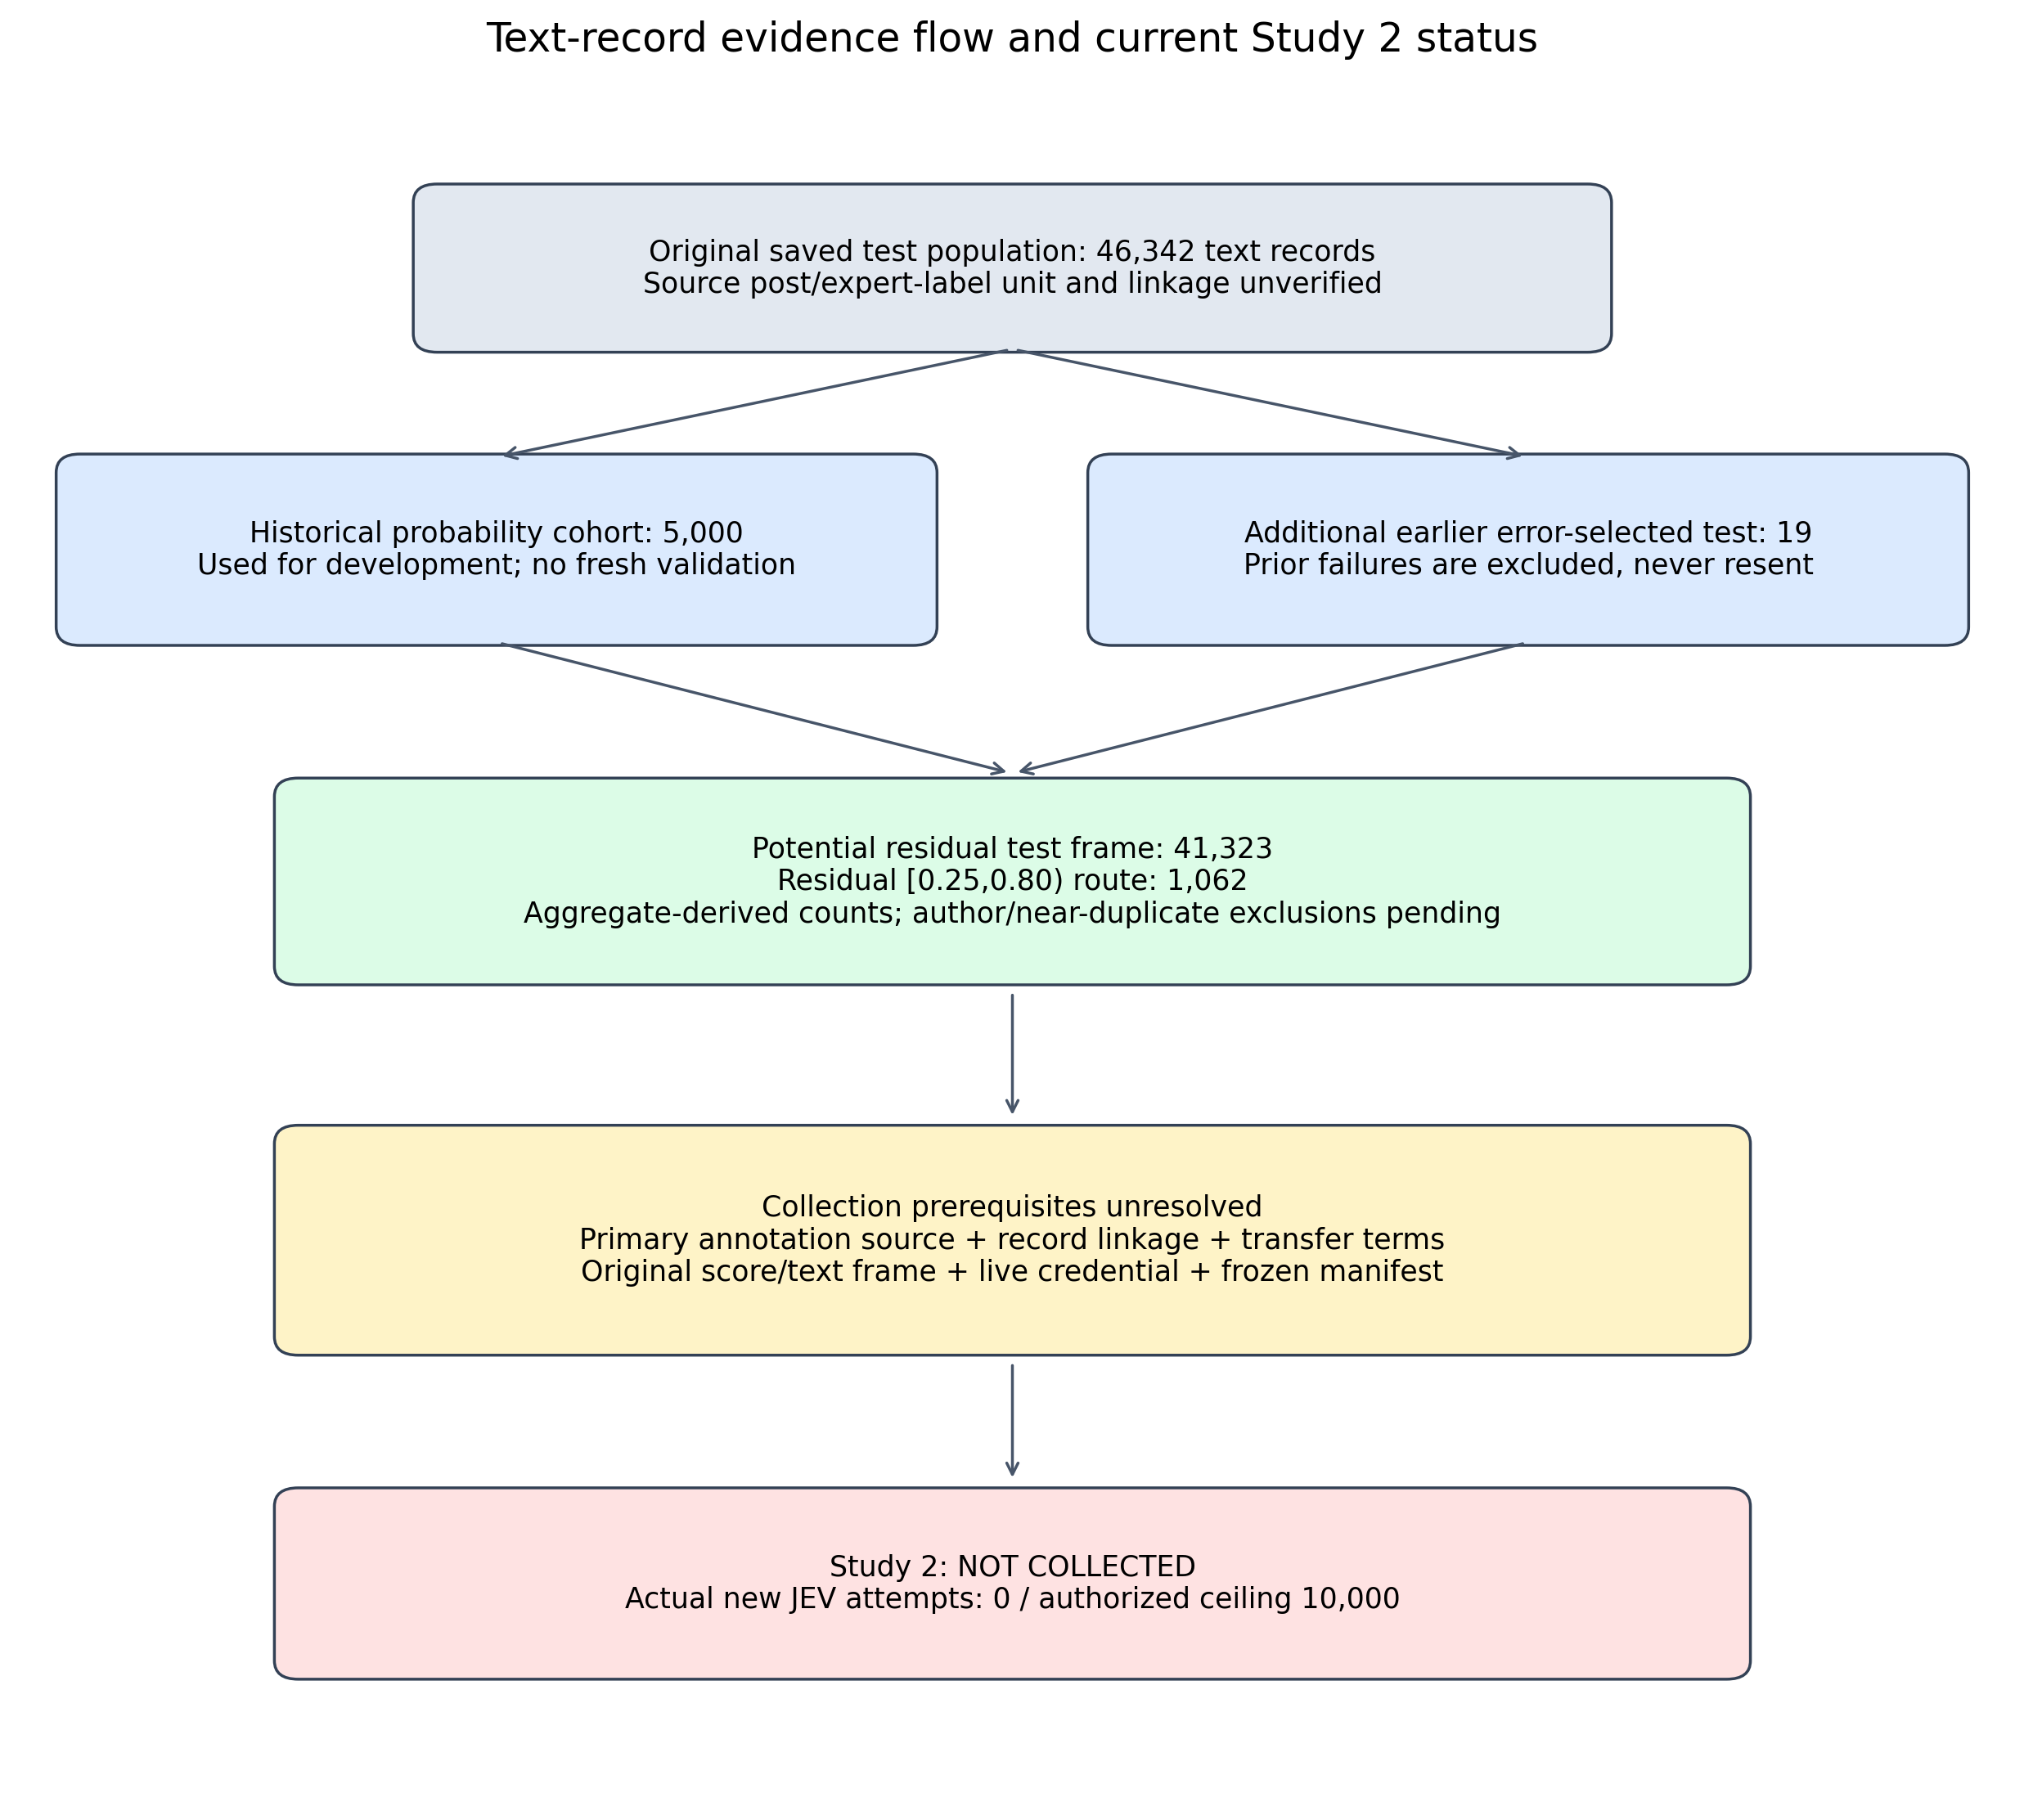

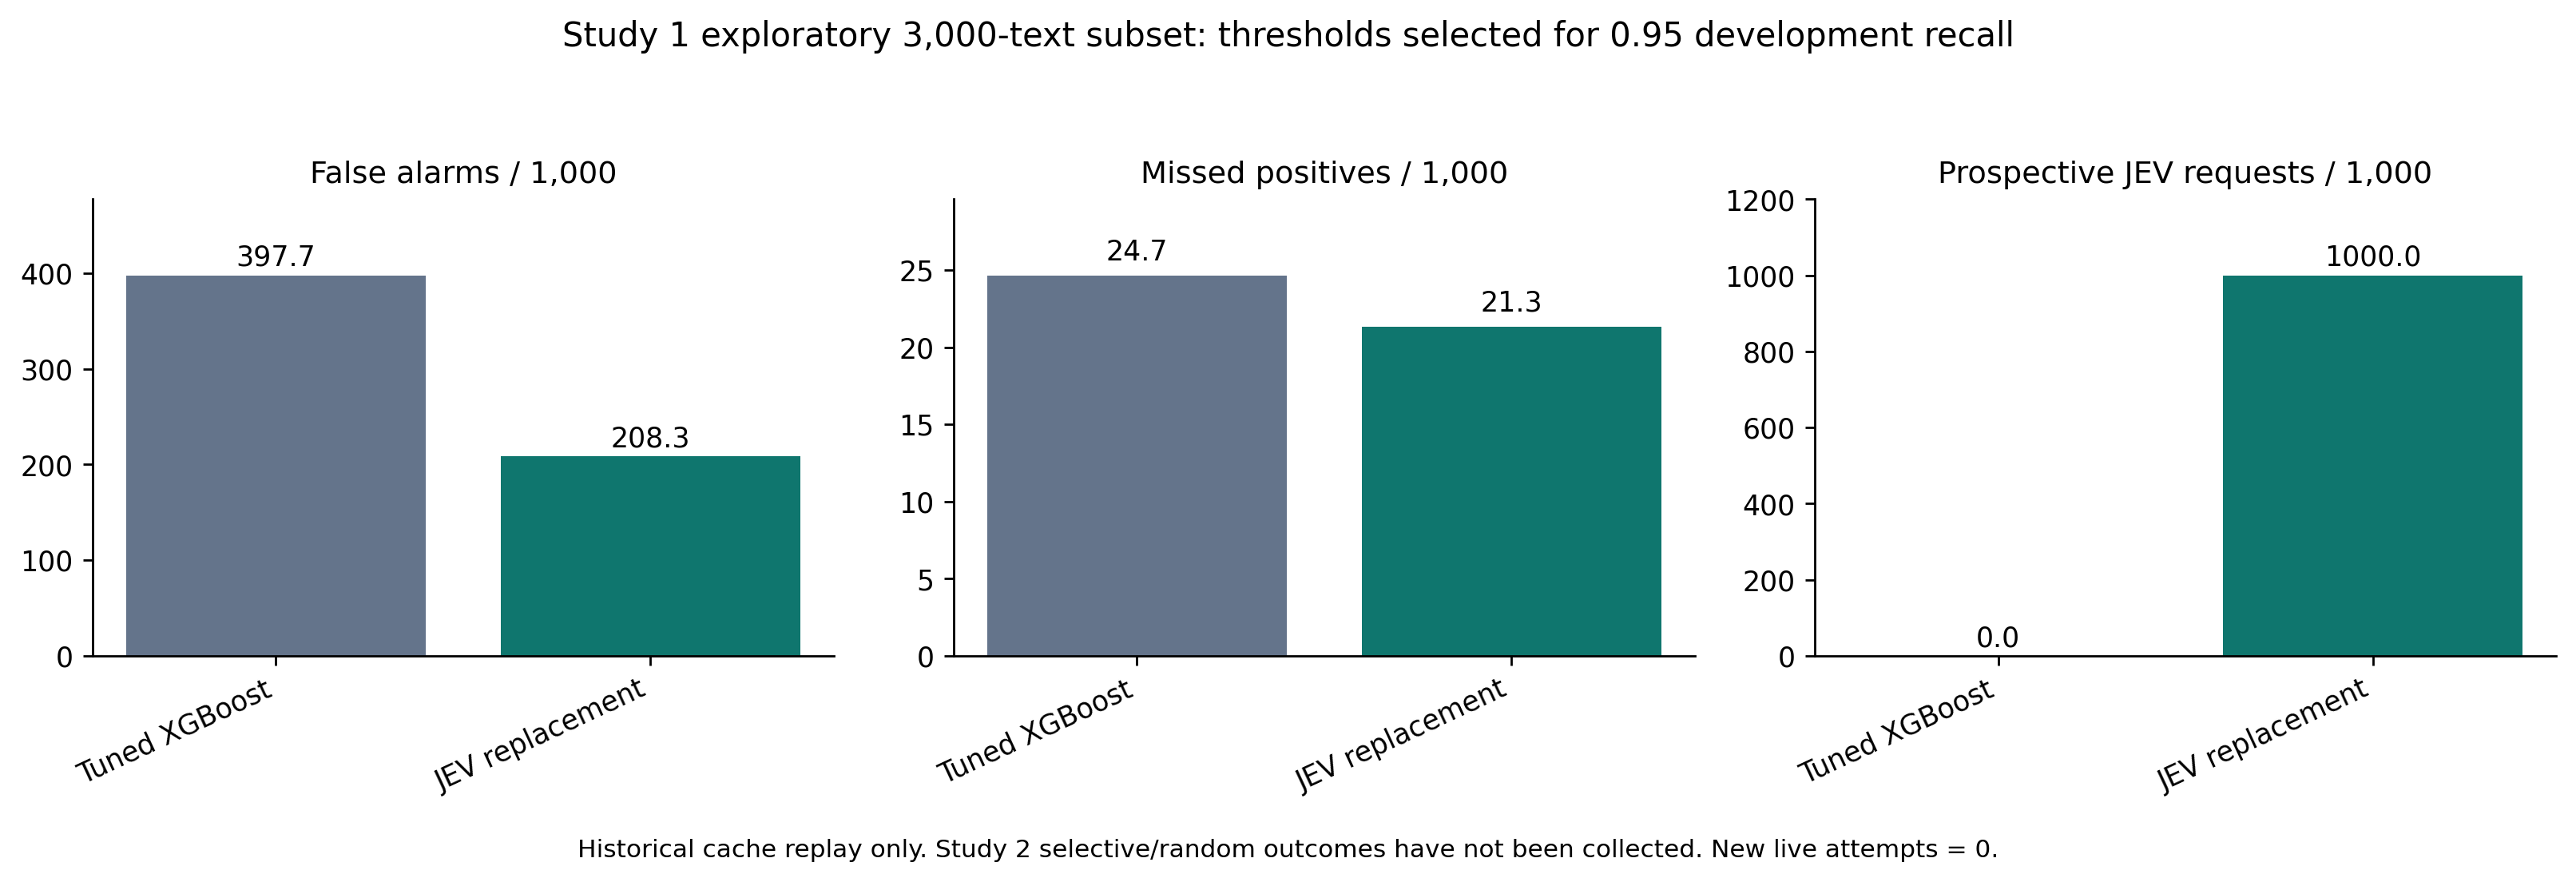

In [9]:
display(Image(filename=str(figures/'post_flow.png')))
display(Image(filename=str(figures/'policy_outcomes_and_request_burden.png')))

## 9. Ethics, access and manuscript claims

Source approval/exemption, consent, release license, current-study review and
permission to send these texts to JEV are distinct and presently unverified.
Public availability is not itself a license or verified external-transfer
permission. Raw text, author identifiers, credentials and provider payloads
stay outside public artifacts. The exact prompt, parser, thresholds, fallback,
model alias, fingerprints and collection status are retained.

Clinical-prediction reporting domains, including relevant TRIPOD+AI concerns,
are assessed below without asserting completed clinical validation or guideline
compliance. No prediction of future behavior, diagnosis, intervention benefit or
clinical readiness is inferred from social-media binary labels. The manuscript
has paper-shaped methods/development results, but is not ready to claim a
completed expert-reference Study 2 while the primary source and collection are
missing.

In [10]:
display(reviewer)
print('Manuscript draft:',results/'manuscript_report.md')
print('Protocol:',results/'protocol.json')
print('No public preregistration or completed Study 2 effect is asserted.')

,likely_reviewer_concern,evidence_supplied,unresolved_limitation,wording_the_manuscript_can_defend
0,Are the labels expert judgments of individual ...,Owner supplied IEEE 9591887 link; repository t...,Primary paper inaccessible; no record mapping ...,Supplied binary labels; specialist-reference c...
1,Does Study 2 provide independent validation?,Historical population exclusions enumerated; l...,No fresh data collected; old test labels were ...,Study 1 exploratory development evidence; Stud...
2,Is preserved sensitivity established?,Paired historical intervals and explicit decis...,No justified clinical noninferiority margin or...,Estimate sensitivity differences; nonsignifica...
3,Does selective routing beat random at equal cost?,Same JEV threshold/fallback; population referr...,No outside-range JEV scores or fresh common sa...,Random-routing superiority is not estimable fr...
4,Are uncertain failures and charges counted?,"Atomic retained cap tests, failure/restart tes...","No live credential, observed price or provider...",Zero new real attempts; 10000 remains unused; ...
5,Are repeat outputs stable?,21 overlap pairs; decisions recalculated at th...,Error-enriched repeat set; mutable alias; n=21,1/21 changed at .03 and 0/21 at .08/.50; wide ...
6,Would a strong local model perform similarly?,Training-only word/character TF-IDF logistic p...,Original raw upstream training/development dat...,Local baseline implemented and unrun on real r...
7,What explains psychologically consequential er...,Separate probability/enriched review samples a...,"Primary construct definitions, text and qualif...",New human coding pending; no generated expert ...
8,Are source ethics and external transfer permit...,Provenance table distinguishes source and curr...,"Source approval, current approval, consent, li...",No current clinical/ethics approval or externa...
9,Is reporting clinically interpretable?,Per-1000 flags/errors/requests and paired desi...,"No future suicide outcome, intervention effect...",Post-label prediction under a pending construc...


Manuscript draft: /workspace/suicide-detection-from-text-with-jev/research/results/jev_selective_routing_study2_validation/manuscript_report.md
Protocol: /workspace/suicide-detection-from-text-with-jev/research/results/jev_selective_routing_study2_validation/protocol.json
No public preregistration or completed Study 2 effect is asserted.


## 10. Verify offline work and preserve the real authorization

Run the legacy and new suites separately. All inference transports are mocked.
The new suite verifies label-blind sampling/exclusions, population budget matching
despite oversampling, finite-frame bootstrap, unit mismatch, source/transfer
gates, cap accounting, failure/resume, digest round trips and a 400-request
**synthetic** integration run followed by read-only replay. That synthetic ledger
is temporary; it is never the real Study 2 ledger. A strong-local-baseline test
checks training-only vocabulary without fitting a real research model.

In [11]:
verification={}
for name,start in [('legacy','tests'),('study2','tests/study2')]:
    process=subprocess.run([sys.executable,'-m','unittest','discover','-s',start,'-v'],
                           cwd=ROOT,text=True,capture_output=True,timeout=180)
    log=process.stdout+process.stderr
    (private/(name+'_verification.log')).write_text(log)
    match=re.search(r'Ran (\d+) tests?',log)
    assert process.returncode==0 and match and int(match.group(1))>0,log[-5000:]
    verification[name+'_tests_passed']=int(match.group(1))
    print(name,':','\n'.join(log.strip().splitlines()[-4:]))
assert verification['legacy_tests_passed']==101
assert {str(p.relative_to(ROOT)):file_digest(p) for p in protected}==before
actual=ledger_status(private/'budget.sqlite3')
verification.update({'real_execution':actual,'prior_artifacts_unchanged':True,'notebook_HTTP_disabled':True,
                     'mock_requests_are_not_real_attempts':True})
save_json(results/'verification.json',verification)
repro={'study2_analysis_sha256':file_digest(ROOT/'jev_research/study2.py'),
       'study2_collection_sha256':file_digest(ROOT/'jev_research/study2_collection.py'),
       'study2_outputs_sha256':file_digest(ROOT/'jev_research/study2_outputs.py'),
       'notebook_builder_sha256':file_digest(ROOT/'scripts/build_study2_notebook.py'),
       'protocol_sha256':digest(protocol),'seed':RANDOM_SEED,'historical_file_fingerprints':before,
       'source_revision':protocol['source_revision']}
import importlib.metadata,platform
repro['dependencies']={'python':platform.python_version(),**{p:importlib.metadata.version(p) for p in ['numpy','pandas','scipy','scikit-learn','matplotlib','nbclient','requests']}}
save_json(results/'reproducibility.json',repro)
display(pd.Series(verification))
guard.stop()

legacy : ----------------------------------------------------------------------
Ran 101 tests in 8.731s

OK


study2 : ----------------------------------------------------------------------
Ran 20 tests in 3.027s

OK


legacy_tests_passed                                                                  101
study2_tests_passed                                                                   20
real_execution                         {'actual_new_attempts': 0, 'successes': 0, 'fa...
prior_artifacts_unchanged                                                           True
notebook_HTTP_disabled                                                              True
mock_requests_are_not_real_attempts                                                 True
dtype: object

False

## 11. Handoff: measured result, independence and outstanding prerequisites

The supported finding is historical: JEV can reduce false alarms at similar
achieved sensitivity on the reused difficult subset. No fresh expert-reference
effect, sensitivity-preservation decision or selective-over-random advantage
has been established by Study 2. Its independence level is currently **none**,
because no fresh population has been collected. Reusing unqueried old-test
posts later would still require disclosure of prior aggregate test exposure.

Actual additional attempts and unused allowance are shown below from the real
ledger status. The owner has already authorized the 10,000 ceiling; no further
financial confirmation is needed. What is missing is the primary annotation
source/linkage and compatible data terms, a complete original or independently
collected score/text/reference frame, usable access and secure authentication.
Once these exist, freeze the concrete versioned package and run the separate
collector in `research/study2_collection_and_reporting.md`. Do not turn notebook
Run All into paid collection, repurchase historical failures, substitute generated
expert judgments or choose the evaluation threshold after seeing outcomes.

In [12]:
display(pd.Series(ledger_status(private/'budget.sqlite3'),name='Real Study 2 attempt accounting'))
print('Human source-label verification and focused qualified review remain pending.')
print('Live command is separate: python -m jev_research.study2_collection --collect ...')

actual_new_attempts                                          0
successes                                                    0
failed                                                       0
pending_uncertain                                            0
unused_allowance                                         10000
ledger_exists                                            False
study_id               jev_selective_routing_study2_validation
Name: Real Study 2 attempt accounting, dtype: object

Human source-label verification and focused qualified review remain pending.
Live command is separate: python -m jev_research.study2_collection --collect ...
